# Tree Ensembles
I will train a Decision Tree, a Random Forest and an XGBoost model on a heart disease dataset, and compare how each one overfits.

In [4]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

RANDOM_STATE = 55

### Load the dataset
I load the heart disease CSV into a pandas DataFrame and check its shape and column names to confirm it is the right file.

In [5]:
df = pd.read_csv("heart.csv")
print(df.shape)
print(df.columns.tolist())

(918, 12)
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


### Inspect the data
I look at the first few rows to see which columns hold text instead of numbers, since the models can only work with numbers.

In [6]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### One-hot encoding
The 5 categorical columns hold text, so I convert each one into separate 0/1 columns, one per category, using pandas get_dummies.

In [7]:
cat_variables = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

df = pd.get_dummies(data=df, prefix=cat_variables, columns=cat_variables)
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True


### Split the data
I separate the input features from the target column, then split the data 80/20 into a training set and a validation set to measure overfitting later.

In [8]:
features = [x for x in df.columns if x !='HeartDisease']
X_train,X_val,y_train,y_val = train_test_split(df[features],df['HeartDisease'],train_size = 0.8,random_state = RANDOM_STATE)
print(X_train.shape,X_val.shape)

(734, 20) (184, 20)


### Decision tree: min_samples_split
I train a decision tree for several values of min_samples_split and compare training accuracy against validation accuracy to see where the tree starts overfitting.

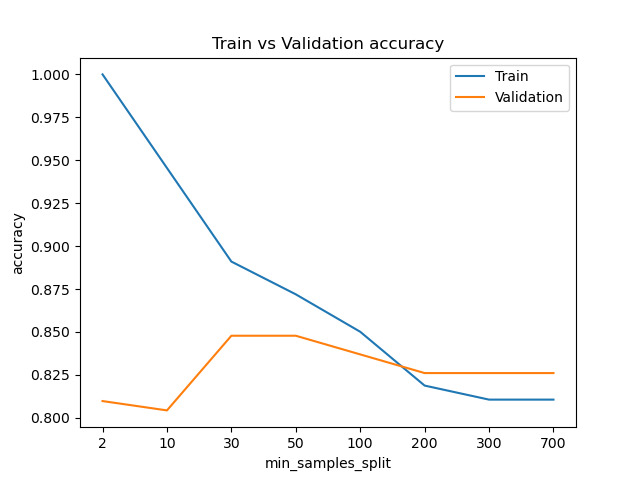

In [10]:
min_samples_split_list = [2, 10, 30, 50, 100, 200, 300, 700]

accuracy_list_train = []
accuracy_list_val = []

for min_samples_split in min_samples_split_list:
    model = DecisionTreeClassifier(min_samples_split=min_samples_split, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    predictions_train = model.predict(X_train)
    predictions_val = model.predict(X_val)

    accuracy_list_train.append(accuracy_score(y_train, predictions_train))
    accuracy_list_val.append(accuracy_score(y_val, predictions_val))

plt.title('Train vs Validation accuracy')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks=range(len(min_samples_split_list)), labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])
plt.savefig("tree_min_samples_split.png")
plt.close()
from IPython.display import Image
Image("tree_min_samples_split.png")

### Decision tree: max_depth
I train a decision tree for several values of max_depth and compare training accuracy against validation accuracy, to find the depth where the tree stops improving on new data.

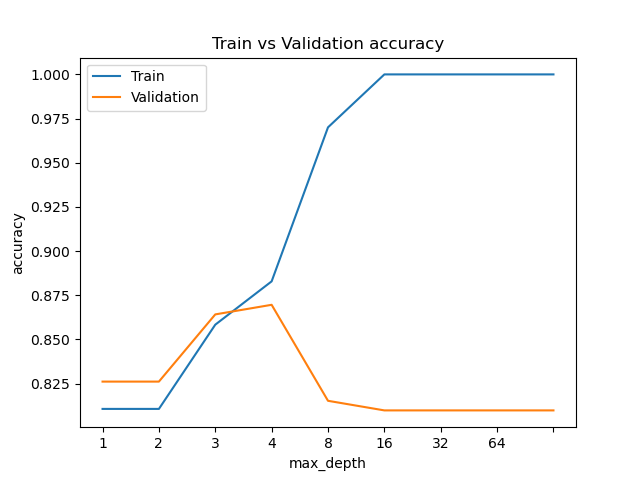

In [11]:
max_depth_list = [1, 2, 3, 4, 8, 16, 32, 64, None]

accuracy_list_train = []
accuracy_list_val = []

for max_depth in max_depth_list:
    model = DecisionTreeClassifier(max_depth=max_depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    predictions_train = model.predict(X_train)
    predictions_val = model.predict(X_val)

    accuracy_list_train.append(accuracy_score(y_train, predictions_train))
    accuracy_list_val.append(accuracy_score(y_val, predictions_val))

plt.title('Train vs Validation accuracy')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks=range(len(max_depth_list)), labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])
plt.savefig("tree_max_depth.png")
plt.close()
from IPython.display import Image
Image("tree_max_depth.png")

### Final decision tree
I combine the best max_depth and min_samples_split values found from the two plots, and measure train and validation accuracy for the final tree.

In [12]:
decision_tree_model = DecisionTreeClassifier(min_samples_split=50, max_depth=3, random_state=RANDOM_STATE)
decision_tree_model.fit(X_train, y_train)

print(f"Metrics train:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_train), y_train):.4f}")
print(f"Metrics validation:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_val), y_val):.4f}")

Metrics train:
	Accuracy score: 0.8583
Metrics validation:
	Accuracy score: 0.8641


### Random Forest: min_samples_split
I train a random forest for several values of min_samples_split and compare training accuracy against validation accuracy, to see how a forest of trees overfits compared to a single tree.

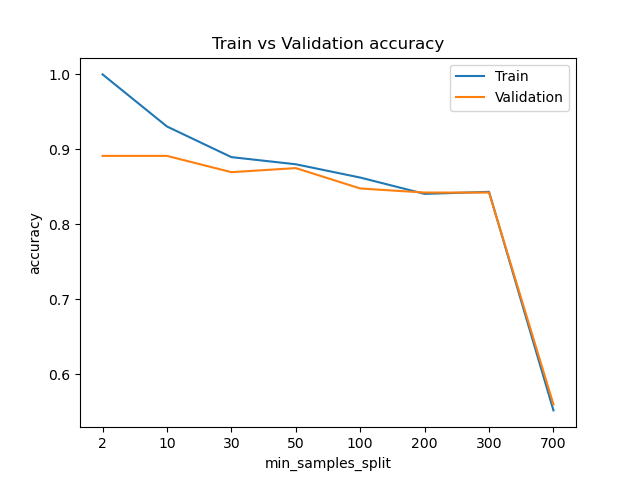

In [14]:
min_samples_split_list = [2, 10, 30, 50, 100, 200, 300, 700]

accuracy_list_train = []
accuracy_list_val = []

for min_samples_split in min_samples_split_list:
    model = RandomForestClassifier(min_samples_split=min_samples_split, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    predictions_train = model.predict(X_train)
    predictions_val = model.predict(X_val)

    accuracy_list_train.append(accuracy_score(y_train, predictions_train))
    accuracy_list_val.append(accuracy_score(y_val, predictions_val))

plt.title('Train vs Validation accuracy')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks=range(len(min_samples_split_list)), labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])
plt.savefig("forest_min_samples_split.png")
plt.close()
from IPython.display import Image
Image("forest_min_samples_split.png")

### Random Forest: max_depth
I train a random forest for several values of max_depth and compare training accuracy against validation accuracy, to see how depth affects overfitting inside a forest.


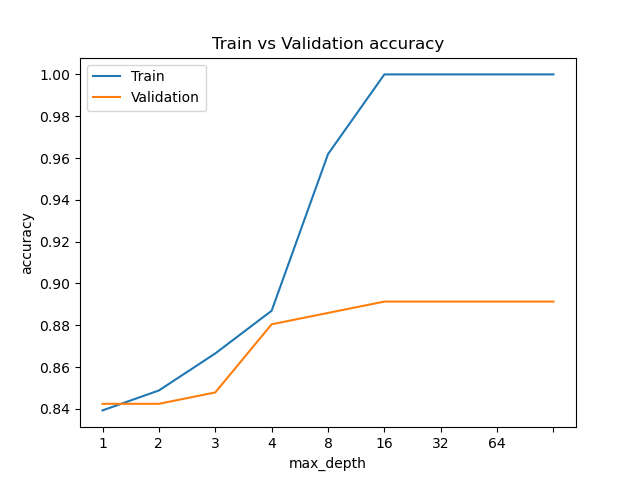

In [15]:
max_depth_list = [1, 2, 3, 4, 8, 16, 32, 64, None]

accuracy_list_train = []
accuracy_list_val = []

for max_depth in max_depth_list:
    model = RandomForestClassifier(max_depth=max_depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    predictions_train = model.predict(X_train)
    predictions_val = model.predict(X_val)

    accuracy_list_train.append(accuracy_score(y_train, predictions_train))
    accuracy_list_val.append(accuracy_score(y_val, predictions_val))

plt.title('Train vs Validation accuracy')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks=range(len(max_depth_list)), labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])
plt.savefig("forest_max_depth.png")
plt.close()
from IPython.display import Image
Image("forest_max_depth.png")

### Random Forest: n_estimators
I train a random forest with different numbers of trees and compare training accuracy against validation accuracy, to see how many trees are worth using.

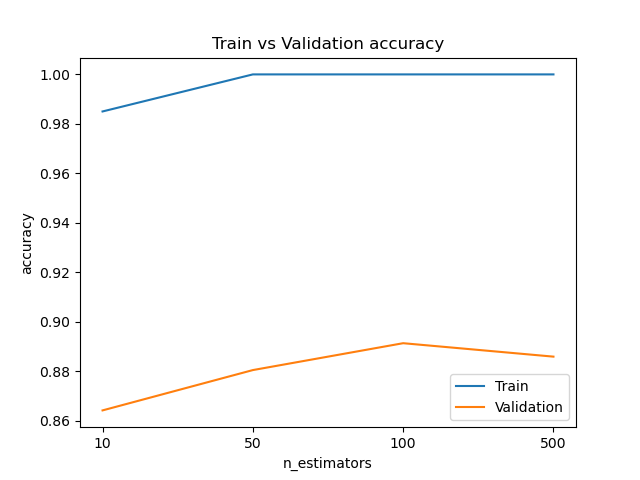

In [16]:
n_estimators_list = [10, 50, 100, 500]

accuracy_list_train = []
accuracy_list_val = []

for n_estimators in n_estimators_list:
    model = RandomForestClassifier(n_estimators=n_estimators, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)

    predictions_train = model.predict(X_train)
    predictions_val = model.predict(X_val)

    accuracy_list_train.append(accuracy_score(y_train, predictions_train))
    accuracy_list_val.append(accuracy_score(y_val, predictions_val))

plt.title('Train vs Validation accuracy')
plt.xlabel('n_estimators')
plt.ylabel('accuracy')
plt.xticks(ticks=range(len(n_estimators_list)), labels=n_estimators_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])
plt.savefig("forest_n_estimators.png")
plt.close()
from IPython.display import Image
Image("forest_n_estimators.png")

### Final Random Forest
I combine the best n_estimators, max_depth and min_samples_split values found from the plots into one random forest, and measure its train and validation accuracy.

In [17]:
random_forest_model = RandomForestClassifier(n_estimators=100, max_depth=16, min_samples_split=10, random_state=RANDOM_STATE)
random_forest_model.fit(X_train, y_train)

print(f"Metrics train:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_train), y_train):.4f}")
print(f"Metrics validation:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_val), y_val):.4f}")

Metrics train:
	Accuracy score: 0.9305
Metrics validation:
	Accuracy score: 0.8913


### XGBoost
Trains trees one after another, where each new tree tries to fix the errors of the ones before it, and stops early once the validation metric stops improving.

In [18]:
n = int(len(X_train)*0.8)
print(n)

587


In [19]:
X_train_fit, X_train_eval, y_train_fit, y_train_eval = X_train[:n], X_train[n:], y_train[:n], y_train[n:]
print(len(X_train_fit), len(X_train_eval))

587 147


In [20]:
xgb_model = XGBClassifier(n_estimators=500, learning_rate=0.1, early_stopping_rounds=10, random_state=RANDOM_STATE)

In [21]:
xgb_model.fit(X_train_fit, y_train_fit, eval_set=[(X_train_eval, y_train_eval)], verbose=True)

[0]	validation_0-logloss:0.63301
[1]	validation_0-logloss:0.59553
[2]	validation_0-logloss:0.56612
[3]	validation_0-logloss:0.54186
[4]	validation_0-logloss:0.52348
[5]	validation_0-logloss:0.50610
[6]	validation_0-logloss:0.49371
[7]	validation_0-logloss:0.48365
[8]	validation_0-logloss:0.47321
[9]	validation_0-logloss:0.46537
[10]	validation_0-logloss:0.45999
[11]	validation_0-logloss:0.45620
[12]	validation_0-logloss:0.45482
[13]	validation_0-logloss:0.44974
[14]	validation_0-logloss:0.44494
[15]	validation_0-logloss:0.44072
[16]	validation_0-logloss:0.44078
[17]	validation_0-logloss:0.43935
[18]	validation_0-logloss:0.44206
[19]	validation_0-logloss:0.44536
[20]	validation_0-logloss:0.44321
[21]	validation_0-logloss:0.44310
[22]	validation_0-logloss:0.44419
[23]	validation_0-logloss:0.44797
[24]	validation_0-logloss:0.44843
[25]	validation_0-logloss:0.45337
[26]	validation_0-logloss:0.45206
[27]	validation_0-logloss:0.45435


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,10
,enable_categorical,True
,eval_metric,None


In [22]:
xgb_model.best_iteration

17

In [23]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_train), y_train):.4f}")
print(f"Metrics validation:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_val), y_val):.4f}")

Metrics train:
	Accuracy score: 0.9319
Metrics validation:
	Accuracy score: 0.8533


### Summary
In this lab I one-hot encoded the heart disease dataset with pandas and trained a decision tree, a random forest and an XGBoost model with scikit-learn. I tuned the tree and forest hyperparameters by plotting train against validation accuracy, and used early stopping on a held-out eval set to decide how many XGBoost trees to keep. The tree ensembles reached similar validation accuracy, with the forest and XGBoost ahead of the single decision tree.